<a href="https://colab.research.google.com/github/manitousi123/Predict-Machine-Failures-with-ML/blob/main/Predict_Machine_Failures_with_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!pip install ucimlrepo imbalanced-learn shap

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve, auc
from sklearn.dummy import DummyClassifier
from imblearn.over_sampling import SMOTE
import shap
import warnings
warnings.filterwarnings('ignore')

In [7]:
# Load the dataset
from ucimlrepo import fetch_ucirepo
dataset = fetch_ucirepo(id=601)
X = dataset.data.features
y = dataset.data.targets

# Combine into a single DataFram for exploration
df = pd.concat([X, y], axis=1)
print(f"Dataset shape: {df.shape}")
print(f"\nColumn names: {df.columns.tolist()}")
print(f"\nFirst 5 rows:")
print(df.head())

Dataset shape: (10000, 12)

Column names: ['Type', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

First 5 rows:
  Type  Air temperature  Process temperature  Rotational speed  Torque  \
0    M            298.1                308.6              1551    42.8   
1    L            298.2                308.7              1408    46.3   
2    L            298.1                308.5              1498    49.4   
3    L            298.2                308.6              1433    39.5   
4    L            298.2                308.7              1408    40.0   

   Tool wear  Machine failure  TWF  HDF  PWF  OSF  RNF  
0          0                0    0    0    0    0    0  
1          3                0    0    0    0    0    0  
2          5                0    0    0    0    0    0  
3          7                0    0    0    0    0    0  
4          9                0    0    0    0    0    0  


In [8]:
# Check class distribution
print(f"\nClass distribution:")
print(df['Machine failure'].value_counts())
print(f"\nFailure rate: {df['Machine failure'].mean()*100:.1f}%")


Class distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure rate: 3.4%


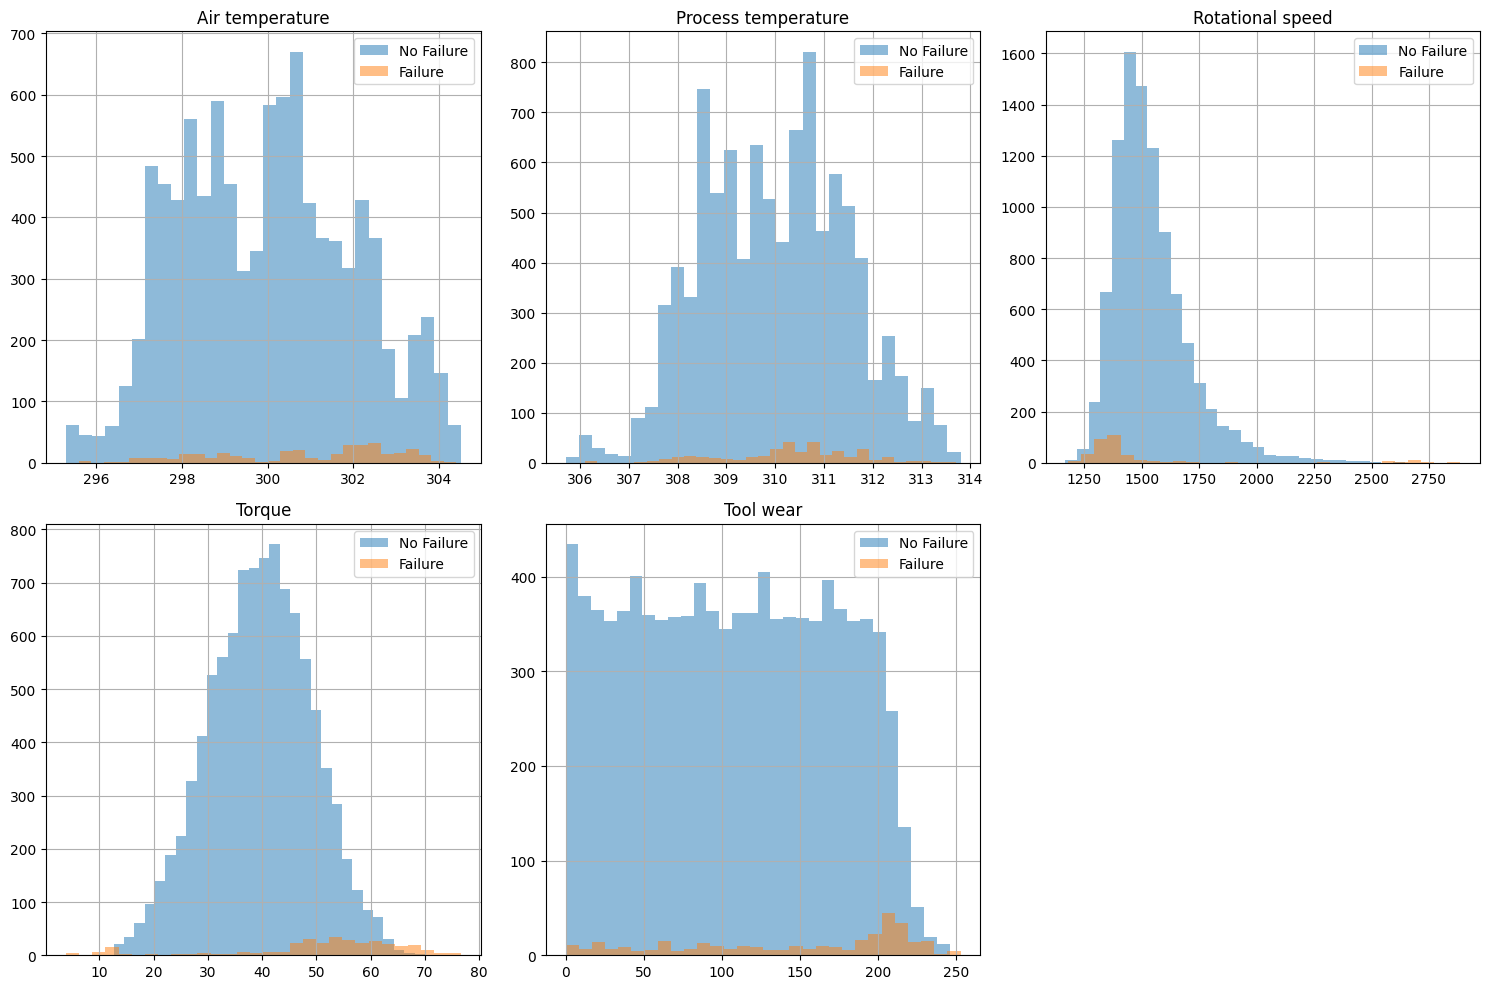

In [9]:
# --- Step 2: EDA and Feature Engineering ---

# Separate numerical and categorical features
numerical_cols = ['Air temperature', 'Process temperature',
                  'Rotational speed', 'Torque', 'Tool wear']
categorical_col = 'Type'

# Plot feature distributions by failure class
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for idx, col in enumerate(numerical_cols):
    ax = axes[idx // 3, idx % 3]
    df[df['Machine failure'] == 0][col].hist(ax=ax, alpha=0.5, label='No Failure', bins=30)
    df[df['Machine failure'] == 1][col].hist(ax=ax, alpha=0.5, label='Failure', bins=30)
    ax.set_title(col)
    ax.legend()
axes[1, 2].axis('off')
plt.tight_layout()
plt.show()

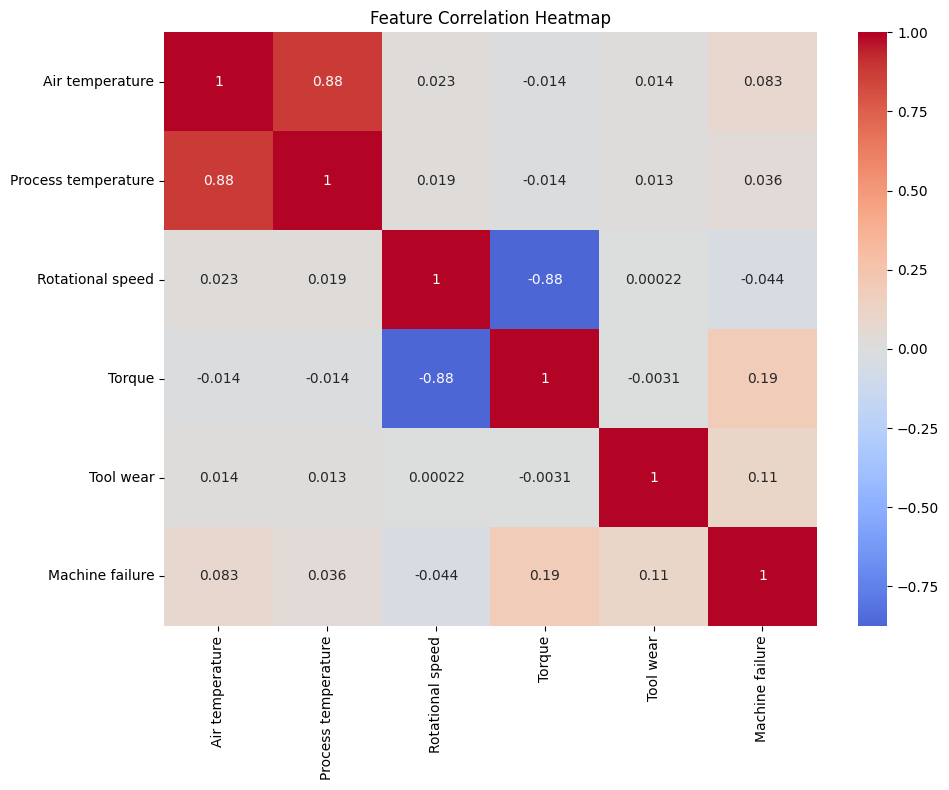

In [10]:
# Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df[numerical_cols + ['Machine failure']].corr(), annot=True, cmap='coolwarm', center=0)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

In [11]:
# Engineer physics-inspired features
df['power'] = df['Torque'] * (df['Rotational speed'] * 2 * np.pi / 60)
df['thermal_gradient'] = df['Process temperature'] - df['Air temperature']
df['strain_index'] = df['Tool wear'] * df['Torque']

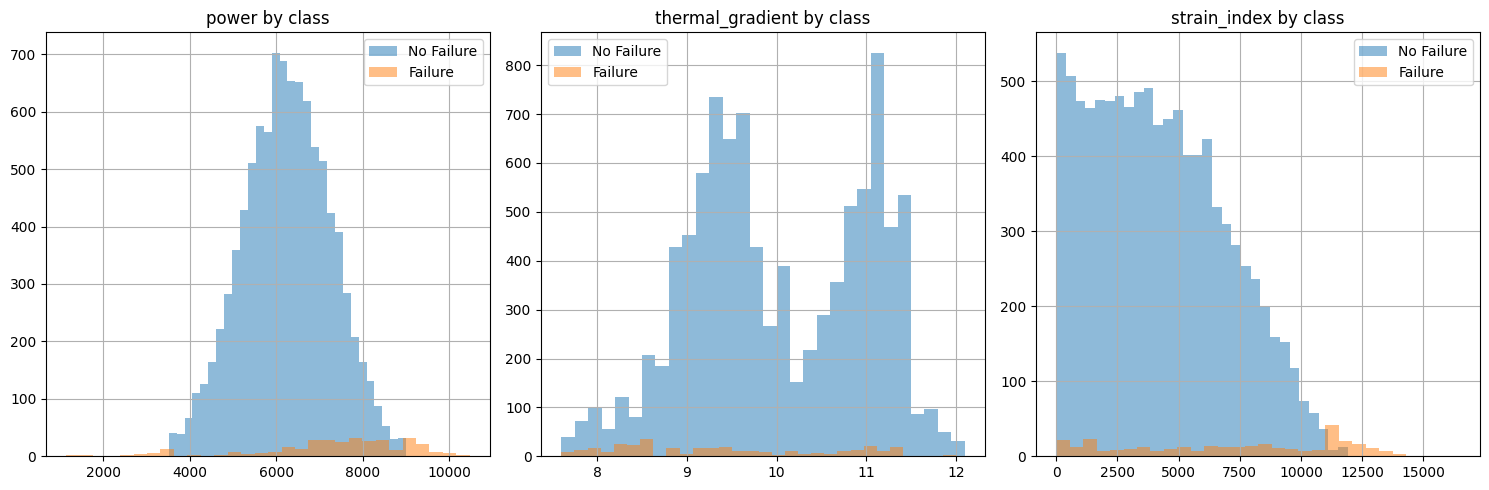

In [12]:
# Visualize engineered features by class
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
engineered_features = ['power', 'thermal_gradient', 'strain_index']
for idx, col in enumerate(engineered_features):
    ax = axes[idx]
    df[df['Machine failure'] == 0][col].hist(ax=ax, alpha=0.5, label='No Failure', bins=30)
    df[df['Machine failure'] == 1][col].hist(ax=ax, alpha=0.5, label='Failure', bins=30)
    ax.set_title(f'{col} by class')
    ax.legend()
plt.tight_layout()
plt.show()

# One-hot encode the Type column
df = pd.get_dummies(df, columns=['Type'], prefix='type')

In [13]:
# --- Step 3: Handle Class Imbalance and Build Pipeline ---

# Prepare features and target
feature_cols = numerical_cols + engineered_features + ['type_H', 'type_L', 'type_M']
target_col = 'Machine failure'

X = df[feature_cols].copy()
y = df[target_col].copy()

# Train/test split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")
print(f"Training failure rate: {y_train.mean()*100:.1f}%")


Training set: 8000 samples
Test set: 2000 samples
Training failure rate: 3.4%


In [14]:
# Apply SMOTE to training data only
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)
print(f"\nAfter SMOTE:")
print(f"Training samples: {X_train_resampled.shape[0]}")
print(f"Class distribution: {pd.Series(y_train_resampled).value_counts().to_dict()}")


After SMOTE:
Training samples: 15458
Class distribution: {0: 7729, 1: 7729}


In [15]:
# Build preprocessing pipeline
numerical_features = numerical_cols + engineered_features
categorical_features = ['type_H', 'type_L', 'type_M']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', 'passthrough', categorical_features)
    ]
)

In [16]:
# Baseline: Dummy classifier (always predicts majority class)
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
print(f"\nDummy classifier accuracy: {dummy.score(X_test, y_test)*100:.1f}%")
print("(This proves accuracy is USELESS for imbalanced data)\n")

# Logistic Regression baseline
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])
lr_pipeline.fit(X_train_resampled, y_train_resampled)
y_pred_lr = lr_pipeline.predict(X_test)
print("=== Logistic Regression ===")
print(classification_report(y_test, y_pred_lr, target_names=['No Failure', 'Failure']))


Dummy classifier accuracy: 96.6%
(This proves accuracy is USELESS for imbalanced data)

=== Logistic Regression ===
              precision    recall  f1-score   support

  No Failure       0.99      0.91      0.95      1932
     Failure       0.24      0.76      0.36        68

    accuracy                           0.91      2000
   macro avg       0.61      0.84      0.66      2000
weighted avg       0.97      0.91      0.93      2000



In [17]:
# --- Step 4: Model Comparison and Tuning ---

# Random Forest
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])
rf_pipeline.fit(X_train_resampled, y_train_resampled)
y_pred_rf = rf_pipeline.predict(X_test)
print("=== Random Forest ===")
print(classification_report(y_test, y_pred_rf, target_names=['No Failure', 'Failure']))

=== Random Forest ===
              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1932
     Failure       0.71      0.78      0.74        68

    accuracy                           0.98      2000
   macro avg       0.85      0.88      0.87      2000
weighted avg       0.98      0.98      0.98      2000



In [18]:
# Gradient Boosting
gb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(n_estimators=100, random_state=42))
])
gb_pipeline.fit(X_train_resampled, y_train_resampled)
y_pred_gb = gb_pipeline.predict(X_test)
print("=== Gradient Boosting ===")
print(classification_report(y_test, y_pred_gb, target_names=['No Failure', 'Failure']))

=== Gradient Boosting ===
              precision    recall  f1-score   support

  No Failure       1.00      0.97      0.98      1932
     Failure       0.51      0.87      0.64        68

    accuracy                           0.97      2000
   macro avg       0.75      0.92      0.81      2000
weighted avg       0.98      0.97      0.97      2000



In [22]:
# Hyperparameter tuning on the best model (Random Forest)
param_distributions = {
    'classifier__n_estimators': [50, 100, 200, 300],
    'classifier__max_depth': [5, 10, 15, 20, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

rf_tuning_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = RandomizedSearchCV(
    rf_tuning_pipeline,
    param_distributions,
    n_iter=20,
    scoring='recall',
    cv=cv,
    random_state=42,
    n_jobs=-1
)
search.fit(X_train_resampled, y_train_resampled)
print(f"\nBest parameters: {search.best_params_}")
print(f"Best CV recall: {search.best_score_:.3f}")


Best parameters: {'classifier__n_estimators': 100, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_depth': 20}
Best CV recall: 0.995


In [23]:
# Final evaluation
best_model = search.best_estimator_
y_pred_best = best_model.predict(X_test)
print("\n=== Best Model (Tuned Random Forest) ===")
print(classification_report(y_test, y_pred_best, target_names=['No Failure', 'Failure']))


=== Best Model (Tuned Random Forest) ===
              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1932
     Failure       0.70      0.82      0.76        68

    accuracy                           0.98      2000
   macro avg       0.85      0.91      0.87      2000
weighted avg       0.98      0.98      0.98      2000



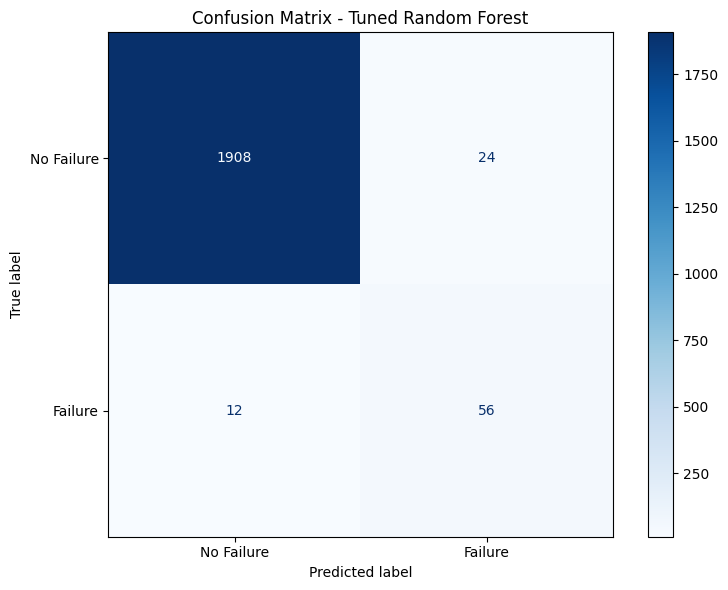

In [24]:
# Confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Failure', 'Failure'])
disp.plot(ax=ax, cmap='Blues')
plt.title('Confusion Matrix - Tuned Random Forest')
plt.tight_layout()
plt.show()

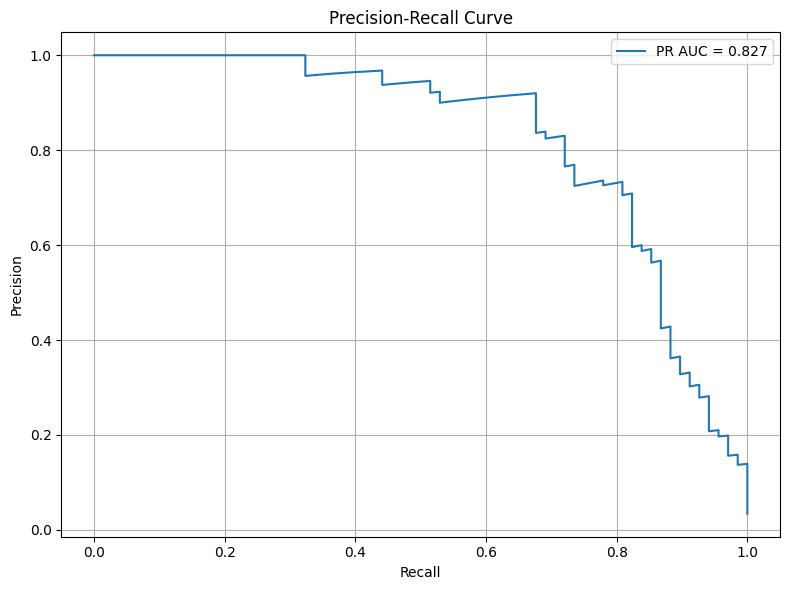

In [25]:
# Precision-Recall curve
y_scores = best_model.predict_proba(X_test)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_test, y_scores)
pr_auc = auc(recall, precision)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'PR AUC = {pr_auc:.3f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

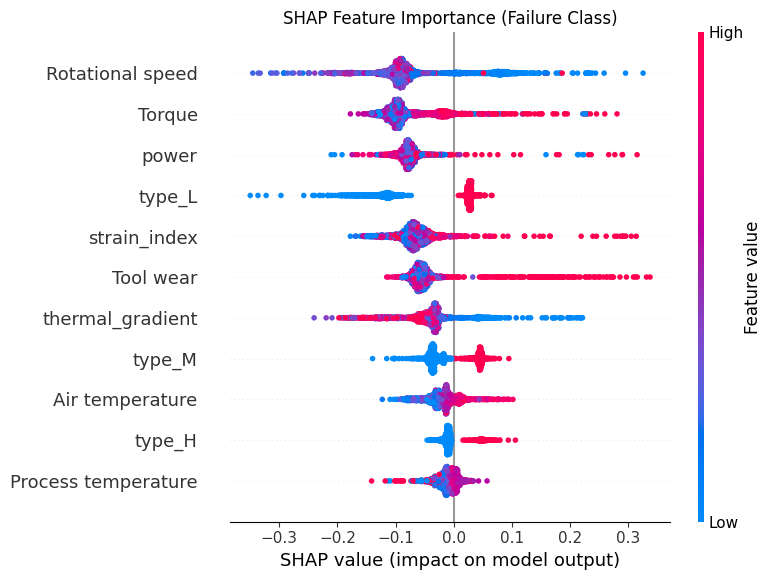

In [26]:
# --- Step 5: SHAP Explanations ---

# Extract the trained classifier from the pipeline
classifier = best_model.named_steps['classifier']
X_test_transformed = best_model.named_steps['preprocessor'].transform(X_test)

# Create SHAP explainer
explainer = shap.TreeExplainer(classifier)
shap_values = explainer.shap_values(X_test_transformed)

# Feature names for display
feature_names = numerical_features + categorical_features

# SHAP summary plot (global feature importance)
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values[..., 1], X_test_transformed, feature_names=feature_names, show=False)
plt.title('SHAP Feature Importance (Failure Class)')
plt.tight_layout()
plt.show()


--- Explaining a correctly predicted FAILURE (test sample 17) ---
Features: {'Air temperature': 303.7, 'Process temperature': 312.1, 'Rotational speed': 1363, 'Torque': 51.8, 'Tool wear': 90, 'power': 7393.570758615386, 'thermal_gradient': 8.400000000000034, 'strain_index': 4662.0, 'type_H': False, 'type_L': True, 'type_M': False}


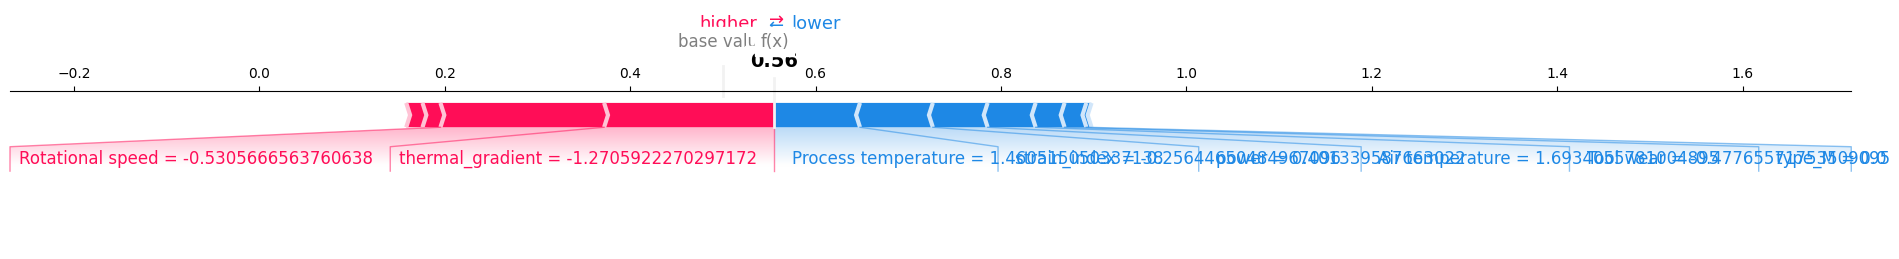


--- Explaining a MISSED failure (test sample 97) ---
Features: {'Air temperature': 300.8, 'Process temperature': 312.4, 'Rotational speed': 1465, 'Torque': 59.1, 'Tool wear': 91, 'power': 9066.793477892823, 'thermal_gradient': 11.599999999999966, 'strain_index': 5378.1, 'type_H': False, 'type_L': True, 'type_M': False}


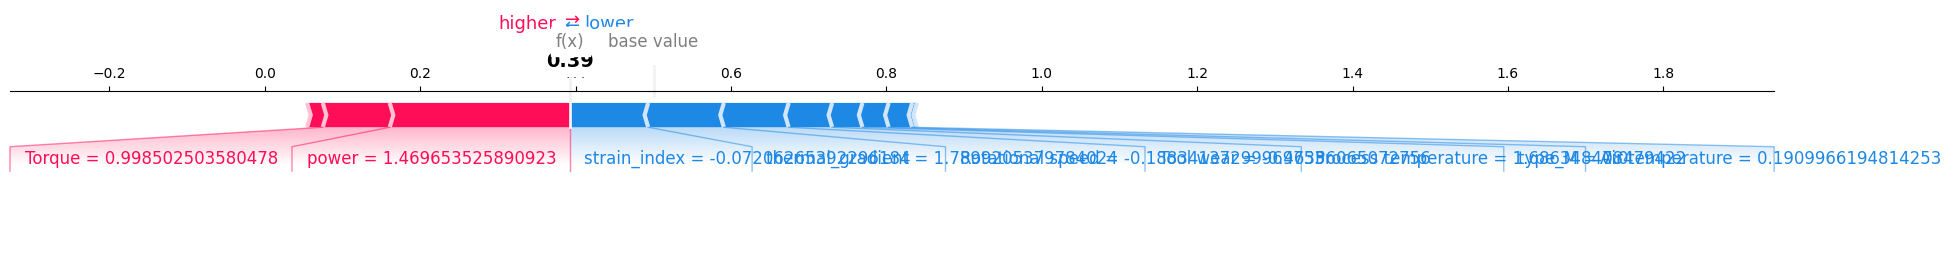

In [27]:
# Individual prediction explanations
def plot_force(idx):
    shap.force_plot(
        explainer.expected_value[1],
        shap_values[idx, :, 1],
        X_test_transformed[idx],
        feature_names=feature_names,
        matplotlib=True,
        show=False,
        contribution_threshold=0.05,   # hide features below 5% of total effect
        figsize=(20, 3)
    )
    plt.tight_layout()
    plt.show()

failure_indices = np.where((y_test.values == 1) & (y_pred_best == 1))[0]
if len(failure_indices) > 0:
    idx = failure_indices[0]
    print(f"\n--- Explaining a correctly predicted FAILURE (test sample {idx}) ---")
    print(f"Features: {X_test.iloc[idx].to_dict()}")
    plot_force(idx)

missed_indices = np.where((y_test.values == 1) & (y_pred_best == 0))[0]
if len(missed_indices) > 0:
    idx = missed_indices[0]
    print(f"\n--- Explaining a MISSED failure (test sample {idx}) ---")
    print(f"Features: {X_test.iloc[idx].to_dict()}")
    plot_force(idx)

In [28]:
print("\n=== Project Complete ===")
print("Your predictive maintenance model can catch machine failures before they happen.")
print("Key insight: Engineered features (strain_index, power) outperform raw sensors.")
print("Key metric: Recall > Accuracy for imbalanced classification.")


=== Project Complete ===
Your predictive maintenance model can catch machine failures before they happen.
Key insight: Engineered features (strain_index, power) outperform raw sensors.
Key metric: Recall > Accuracy for imbalanced classification.


# Project End Notes: Predictive Maintenance (AI4I, Random Forest + SHAP)

## Goal and setup
I built a classifier to predict machine failures from sensor readings. Failures are only 3.4% of the data, so a dummy classifier scores 96.6% accuracy while catching nothing. I therefore judged models on recall and precision, not accuracy. I applied SMOTE to the training set only, which keeps the test set at the real failure rate. I also engineered three physics-inspired features: `power`, `thermal_gradient` and `strain_index`.

## Model selection
I compared Logistic Regression, Random Forest (RF) and Gradient Boosting (GB). On the test set (68 failures):

| Model | Recall | Precision | F1 |
|---|---|---|---|
| Logistic Regression | 0.76 | 0.24 | 0.36 |
| Random Forest | 0.78 | 0.71 | 0.74 |
| Gradient Boosting | 0.87 | 0.51 | 0.64 |
| Random Forest (tuned) | 0.82 | 0.70 | 0.76 |

I chose RF for tuning. GB had the higher recall, but it reached it at much lower precision (0.51 vs 0.71), roughly 57 false alarms against about 24 for the tuned RF. Tuning RF with `RandomizedSearchCV` (20 iterations, 5-fold, recall scoring) lifted test recall from 0.78 to 0.82 with precision unchanged.

**Caveat:** I did not tune GB, so this comparison is preliminary. With only 68 positives, a recall gap of 0.87 vs 0.82 is about 3 samples, which one split can't distinguish from noise. If missed failures cost much more than false alarms, GB's profile could still be the better pick.

## SHAP findings

**Top features** (mean |SHAP|, failure class), in order:
1. Rotational speed
2. Torque
3. `power`
4. `type_L`
5. `strain_index`
6. Tool wear
7. `thermal_gradient`
8. `type_M`
9. Air temperature
10. `type_H`
11. Process temperature

**Directions**
- Low rotational speed pushes toward failure.
- High torque pushes toward failure.
- High tool wear pushes strongly toward failure.
- Low `thermal_gradient` pushes toward failure.
- High `power` and `strain_index` push toward failure.
- Process temperature contributes little.
- The three product-type features are one variable split across one-hot columns.

**Engineered vs. raw.** The engineered features helped but did not outrank their raw inputs. Rotational speed and torque, both raw, are first and second. `power` (3rd) and `strain_index` (5th) beat raw tool wear and both raw temperatures, and `thermal_gradient` (7th) beats the raw temperatures it is built from. My original conclusion that engineered features outperform raw sensors overstated this. SHAP also splits credit between correlated features, so these ranks understate the shared signal. To test it properly I would retrain without the three engineered features and compare recall.

## Caught vs. missed failure (force plots)
The base value is about 0.5 because of SMOTE, so output scores are not real-world failure probabilities.

- **Sample 17 (caught, $f(x)\approx0.56$):** low speed (1363 rpm), low `thermal_gradient` (8.4) and high torque (51.8) all push toward failure. It only just crossed the 0.5 threshold, so it was a marginal catch.
- **Sample 97 (missed, $f(x)\approx0.39$):** higher speed (1465 rpm) and a wider `thermal_gradient` (11.6) push away from failure. Its high torque (59.1) and high power (9066.8) push toward failure, but not enough to cross the threshold.

The model learned the low-speed, low-temperature-difference failure pattern well. Failures with high load and a healthy speed and temperature profile are under-weighted. I did not confirm sample 97's failure mode. The AI4I sub-labels (HDF, PWF, OSF and so on) would show it.

## Limitations and next steps
- Tune GB with the same search and compare on cross-validated PR-AUC, not a single 0.5-threshold report.
- Lower the decision threshold (say below 0.5) and check whether sample 97 and similar misses flip, and what it costs in precision.
- Run the ablation without engineered features.
- Check whether the misses share a failure mode.
- Results come from one train/test split, so they carry sampling noise.

In [29]:
# Create multi-class target from individual failure mode columns
# First, reload targets that include TWF, HDF, PWF, OSF
targets = dataset.data.targets
failure_modes = targets[['TWF', 'HDF', 'PWF', 'OSF']].copy()

# Create multi-class label: 0=No Failure, 1=TWF, 2=HDF, 3=PWF, 4=OSF
# If multiple modes are active, take the first one (rare edge case)
def assign_failure_mode(row):
    if row['TWF'] == 1:
        return 1
    elif row['HDF'] == 1:
        return 2
    elif row['PWF'] == 1:
        return 3
    elif row['OSF'] == 1:
        return 4
    else:
        return 0

y_multi = failure_modes.apply(assign_failure_mode, axis=1)

print("Multi-class failure distribution:")
labels = ['No Failure', 'TWF', 'HDF', 'PWF', 'OSF']
for i, label in enumerate(labels):
    count = (y_multi == i).sum()
    print(f"  {label}: {count} ({count/len(y_multi)*100:.1f}%)")

Multi-class failure distribution:
  No Failure: 9670 (96.7%)
  TWF: 46 (0.5%)
  HDF: 115 (1.1%)
  PWF: 91 (0.9%)
  OSF: 78 (0.8%)


In [30]:
# Split data
X_train_mc, X_test_mc, y_train_mc, y_test_mc = train_test_split(
    X, y_multi, test_size=0.2, random_state=42, stratify=y_multi
)

# Apply SMOTE for multi-class
smote_mc = SMOTE(random_state=42)
X_train_mc_resampled, y_train_mc_resampled = smote_mc.fit_resample(X_train_mc, y_train_mc)

print(f"\nAfter SMOTE (multi-class):")
print(pd.Series(y_train_mc_resampled).value_counts().sort_index())

# Train multi-class Random Forest
mc_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=200, random_state=42))
])
mc_pipeline.fit(X_train_mc_resampled, y_train_mc_resampled)
y_pred_mc = mc_pipeline.predict(X_test_mc)

# Per-class classification report
print("\n=== Multi-Class Failure Mode Prediction ===")
print(classification_report(y_test_mc, y_pred_mc, target_names=labels))


After SMOTE (multi-class):
0    7736
1    7736
2    7736
3    7736
4    7736
Name: count, dtype: int64

=== Multi-Class Failure Mode Prediction ===
              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1934
         TWF       0.06      0.11      0.08         9
         HDF       0.91      0.91      0.91        23
         PWF       0.94      0.94      0.94        18
         OSF       1.00      0.94      0.97        16

    accuracy                           0.99      2000
   macro avg       0.78      0.78      0.78      2000
weighted avg       0.99      0.99      0.99      2000



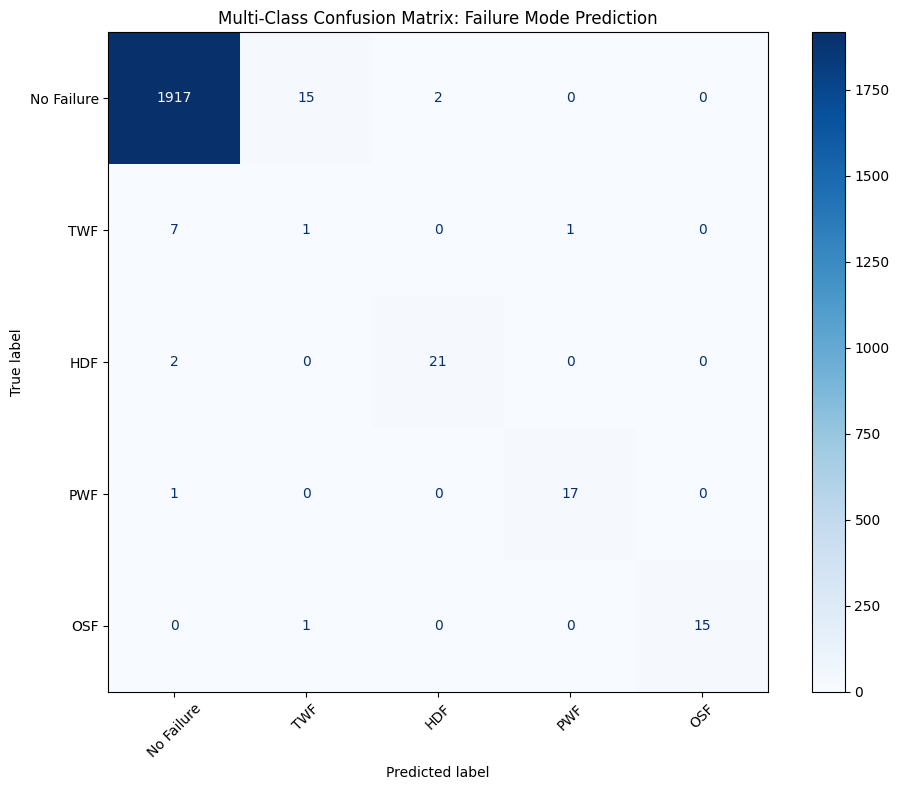


--- Analysis ---
Hardest to predict: Random Failures (RNF) were excluded because
with only 5 occurrences in 10,000 samples, no model can learn them.
TWF (Tool Wear Failure) with only 51 samples is the hardest included mode.
HDF and OSF are easier because their failure mechanisms create clear
feature signatures (thermal gradient < 8.6K for HDF, high strain_index for OSF).


In [31]:
# Multi-class confusion matrix
fig, ax = plt.subplots(figsize=(10, 8))
cm_mc = confusion_matrix(y_test_mc, y_pred_mc)
disp_mc = ConfusionMatrixDisplay(confusion_matrix=cm_mc, display_labels=labels)
disp_mc.plot(ax=ax, cmap='Blues', xticks_rotation=45)
plt.title('Multi-Class Confusion Matrix: Failure Mode Prediction')
plt.tight_layout()
plt.show()

# Analysis
print("\n--- Analysis ---")
print("Hardest to predict: Random Failures (RNF) were excluded because")
print("with only 5 occurrences in 10,000 samples, no model can learn them.")
print("TWF (Tool Wear Failure) with only 51 samples is the hardest included mode.")
print("HDF and OSF are easier because their failure mechanisms create clear")
print("feature signatures (thermal gradient < 8.6K for HDF, high strain_index for OSF).")